In [1]:
from pathlib import Path
from itertools import product
import hashlib
import inspect
import json
import os

import numpy as np
import pandas as pd
from IPython.display import display
from deeprootgen.data_model import RootSimulationModel
from deeprootgen.model import RootSystemSimulation
from deeprootgen.statistics.spatial_rld import calculate_core_rld

In [2]:
# Update INFILE for your checkout. The reference notebooks use ../../data/grapevine/.
INFILE = Path('..', '..', 'data', 'grapevine', 'wong_2026_rld.csv')
if not INFILE.exists() and Path('wong_2026_rld.csv').exists():
    INFILE = Path('wong_2026_rld.csv')
if not INFILE.exists():
    raise FileNotFoundError(f'Cannot find Wong 2026 observations: {INFILE}')

BASE_SEED = 42
CORE_HEIGHT_CM = 10.0  # Assumed 10-cm thick interval, inferred from z_mid_cm spacing.
N_TEST_CORES = 2
N_REPLICATES = 5
LENGTH_SOURCE = 'geometric'  # Matches the geometric segment convention in Fichtl notebooks.

# Wong's independent unit for site-specific spatial validation is the core profile.
# Do not interpret the site management grouping as a grapevine rootstock or timepoint.
SITE = 'Site 1'

# The original Fichtl objective is spatial (0.60), root-order (0.25), length (0.15).
# Wong has diameter classes, not branching orders: substitute a diameter-profile loss.
OBJECTIVE_MODE = 'rld'  # 'composite' enables the much slower diameter-bin calculations.
LOSS_WEIGHTS = {'spatial': 0.60, 'diameter': 0.25, 'length': 0.15}
if OBJECTIVE_MODE not in {'rld', 'composite'}:
    raise ValueError('OBJECTIVE_MODE must be rld or composite.')
if not np.isclose(sum(LOSS_WEIGHTS.values()), 1.0):
    raise ValueError('LOSS_WEIGHTS must sum to 1.')
if CORE_HEIGHT_CM <= 0 or N_REPLICATES < 1:
    raise ValueError('CORE_HEIGHT_CM and N_REPLICATES must be positive.')

# Baseline starting values are adapted from the Fichtl notebooks. They are NOT fitted Wong estimates.
# Wider initial lengths acknowledge that Wong cores extend further laterally/deeply.
BASE_PARAMETERS = dict(
    random_seed=BASE_SEED,
    max_order=5,
    root_ratio=0.5,
    fine_root_threshold=0.15,
    outer_root_num=5,
    inner_root_num=5,
    min_primary_length=15.0,
    max_primary_length=100.0,
    base_diameter=0.5,
    diameter_reduction=0.2,
    apex_diameter=0.05,
    min_sec_root_num=1,
    max_sec_root_num=4,
    growth_sec_root=0.1,
    min_sec_root_length=3.0,
    max_sec_root_length=40.0,
    segments_per_root=8,
    length_reduction=0.7,
    root_vary=10.0,
    interbranch_distance=2.0,
    mechanical_constraints=0.0,
    root_tissue_density=0.15,
    gravitropism=0.5,
    t=1,
    enable_soil=False,
    soil_layer_height=10,
    soil_n_layers=16,
    soil_layer_width=10,
    soil_n_cols=32,
)

In [3]:
DIAMETER_COLS = sorted(
    [c for c in pd.read_csv(INFILE, nrows=0).columns
     if c.startswith('grapevine_length_cm_') and c.endswith('_mm')],
    key=lambda c: float(c.removeprefix('grapevine_length_cm_').split('_')[0]),
)

def diameter_limits(column):
    labels = column.removeprefix('grapevine_length_cm_').removesuffix('_mm').split('_')
    if len(labels) != 2:
        raise ValueError(f'Invalid diameter class: {column}')
    return float(labels[0]), float(labels[1])

DIAMETER_BINS = [(c, *diameter_limits(c)) for c in DIAMETER_COLS]
if not DIAMETER_BINS or any(lo >= hi for _, lo, hi in DIAMETER_BINS):
    raise ValueError('Missing or invalid diameter classes.')

def load_observations(path=INFILE):
    data = pd.read_csv(path)
    required = {
        'site', 'core_id', 'management_grouping', 'x_cm', 'y_cm', 'z_mid_cm',
        'sampled', 'core_volume_cm3', 'grapevine_rld', *DIAMETER_COLS,
    }
    missing = sorted(required.difference(data.columns))
    if missing:
        raise ValueError(f'Missing required fields: {missing}')
    if data.duplicated(['site', 'core_id', 'z_mid_cm']).any():
        raise ValueError('Duplicate site-core-depth records.')
    if not data['sampled'].isin(['Y', 'N']).all():
        raise ValueError('Unrecognised sampled values.')
    if data['core_volume_cm3'].le(0).any():
        raise ValueError('Nonpositive soil core volumes.')
    if data['grapevine_rld'].lt(0).any():
        raise ValueError('Negative root length density.')
    # Unsampled records have zero placeholders; do not fit those records.
    data = data.loc[data['sampled'].eq('Y')].copy()
    if data.empty or data[list(required - {'site', 'core_id', 'management_grouping', 'sampled'})].isna().any().any():
        raise ValueError('Missing values among sampled observations.')
    # The core volume is for an entire 10 cm sampled depth interval, not a 10-cm voxel.
    data['core_radius_cm'] = np.sqrt(data['core_volume_cm3'] / (np.pi * CORE_HEIGHT_CM))
    # DeepRootGen's z axis is negative below ground. z_mid_cm is a positive depth.
    data['z_lower_bound'] = -(data['z_mid_cm'] + CORE_HEIGHT_CM / 2)
    data['z_upper_bound'] = -(data['z_mid_cm'] - CORE_HEIGHT_CM / 2)
    data['observed_length_cm'] = data['grapevine_rld'] * data['core_volume_cm3']
    return data.reset_index(drop=True)

observed_df = load_observations()
print('Sampled records:', len(observed_df), 'Sites:', observed_df.site.nunique(),
      'Core profiles:', observed_df.groupby(['site', 'core_id']).ngroups)

def split_cores(site_observations, seed=BASE_SEED, n_test=N_TEST_CORES):
    cores = np.array(sorted(site_observations['core_id'].unique()))
    if not 0 < n_test < len(cores):
        raise ValueError('N_TEST_CORES must be between 1 and n_cores - 1.')
    permuted = np.random.default_rng(seed).permutation(cores)
    return sorted(permuted[n_test:].tolist()), sorted(permuted[:n_test].tolist())


def site_observations(site):
    result = observed_df.loc[observed_df.site.eq(site)].copy()
    if result.empty:
        raise ValueError(f'Unknown site: {site}')
    # A core profile must have fixed horizontal coordinates.
    if (result.groupby('core_id')[['x_cm', 'y_cm']].nunique() > 1).any().any():
        raise ValueError('Horizontal coordinates vary with depth within a core.')
    return result.reset_index(drop=True)


def sha256_file(path):
    sha = hashlib.sha256()
    with open(path, 'rb') as fh:
        for piece in iter(lambda: fh.read(2**20), b''):
            sha.update(piece)
    return sha.hexdigest()


def configuration_signature(payload):
    # Include source and dataset identity to prevent mixing checkpoint results
    # after changing source, objective, seeds or input observations.
    payload = {
        **payload,
        'data_sha256': sha256_file(INFILE),
        'simulator_sha256': sha256_file(inspect.getfile(RootSystemSimulation)),
        'core_rld_sha256': sha256_file(inspect.getfile(calculate_core_rld)),
    }
    return hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:12]

Sampled records: 880 Sites: 5 Core profiles: 70


In [4]:
import optuna
from optuna.samplers import TPESampler
from optuna.trial import TrialState
import plotly.express as px

OUT_DIR = Path('outputs/wong_2026_optuna_calibration')
OUT_DIR.mkdir(parents=True,exist_ok=True)
GROUPS_TO_FIT = ['Site 1']
N_TRIALS = 40             # Total trials in the persistent study, not per restart.
N_STARTUP_TRIALS = 12
RESUME_OPTUNA = True
SEARCH_SPACE = {
    'max_primary_length': ('float',80.0,180.0),
    'outer_root_num': ('int',3,8),
    'max_sec_root_num': ('int',2,6),
    'max_sec_root_length': ('float',20.0,70.0),
    'interbranch_distance': ('float',1.0,4.0),
    'gravitropism': ('float',0.05,0.5),
}

In [5]:
def predict_cores(parameters, site_data, seed, *, need_diameters=False,
                  return_architecture=False):
    """One simulated RSA per site and seed, evaluated at every selected sampled core.

    Crucially, this does NOT generate an independent plant for every core/depth.
    """
    model = RootSimulationModel(**{**parameters, 'random_seed': int(seed)})
    simulation = RootSystemSimulation(random_seed=int(seed))
    simulation.run(model)
    nodes, edges = simulation.G.as_df()

    # For composite losses, cumulative diameter thresholds are evaluated as
    # real root lengths in the same cylinder. Bin lengths are differences.
    thresholds = sorted({d for _, low, high in DIAMETER_BINS for d in (low, high) if d > 0})
    records = []
    for row in site_data.itertuples(index=False):
        kwargs = dict(
            x=float(row.x_cm), y=float(row.y_cm),
            z_lower_bound=float(row.z_lower_bound),
            z_upper_bound=float(row.z_upper_bound),
            core_radius=float(row.core_radius_cm),
            length_source=LENGTH_SOURCE,
        )
        rld = calculate_core_rld(nodes, **kwargs)
        result = dict(site=row.site, core_id=row.core_id, z_mid_cm=row.z_mid_cm,
                      sim_rld=float(rld),
                      sim_length_cm=float(rld * row.core_volume_cm3))
        if need_diameters:
            cumulative = {0.0: 0.0}
            for threshold in thresholds:
                # Diameter classes are treated as [lower, upper): include values
                # exactly on a bin's lower boundary rather than its upper.
                strict_upper = float(np.nextafter(threshold, -np.inf))
                cumulative[threshold] = calculate_core_rld(
                    nodes, diameter_max_mm=strict_upper, **kwargs
                ) * row.core_volume_cm3
            for column, lower, upper in DIAMETER_BINS:
                result['sim_' + column] = max(
                    0.0, float(cumulative[upper] - cumulative[lower])
                )
        records.append(result)

    prediction = pd.DataFrame(records)
    if return_architecture:
        return prediction, {'seed': int(seed), 'nodes': nodes, 'edges': edges}
    return prediction


def score_prediction(observations, predictions, *, objective_mode=OBJECTIVE_MODE):
    """Compare only genuinely sampled core records, preserving spatial zeros.

    Spatial loss is normalised against a zero-prediction benchmark, as in Fichtl.
    Diameter profiles are optional and not required to sum to reported total RLD.
    """
    keys = ['site', 'core_id', 'z_mid_cm']
    comparison = observations.merge(predictions, on=keys, how='left', validate='one_to_one')
    if comparison['sim_rld'].isna().any():
        raise ValueError('Predictions do not cover every sampled site/core/depth.')
    actual = comparison['grapevine_rld'].to_numpy(float)
    simulated = comparison['sim_rld'].to_numpy(float)
    square = (simulated - actual)**2
    occupied = actual > 0
    if occupied.any() and (~occupied).any():
        mse = 0.5 * (square[occupied].mean() + square[~occupied].mean())
        zero_mse = 0.5 * np.mean(actual[occupied]**2)
    else:
        mse = square.mean()
        zero_mse = np.mean(actual**2)
    # All-zero observations have a zero benchmark loss. Use a squared-error
    # scale of at least 1 to avoid catastrophic division by 1e-12.
    spatial_loss = float(mse / max(zero_mse, 1.0 if not occupied.any() else 1e-12))
    observed_length = float(comparison['observed_length_cm'].sum())
    predicted_length = float(comparison['sim_length_cm'].sum())
    length_loss = float(((predicted_length - observed_length) /
                         max(observed_length, 1e-9))**2)
    if objective_mode == 'composite':
        a = comparison[DIAMETER_COLS].to_numpy(float)
        b = comparison[['sim_' + c for c in DIAMETER_COLS]].to_numpy(float)
        diameter_loss = float(((a - b)**2).sum() / max((a**2).sum(), 1e-12))
        objective = (LOSS_WEIGHTS['spatial'] * spatial_loss +
                     LOSS_WEIGHTS['diameter'] * diameter_loss +
                     LOSS_WEIGHTS['length'] * length_loss)
    elif objective_mode == 'rld':
        diameter_loss = float('nan')
        objective = spatial_loss
    else:
        raise ValueError(f'Unknown objective mode: {objective_mode}')
    comparison['rld_residual'] = comparison['sim_rld'] - comparison['grapevine_rld']
    return comparison, {
        'objective': float(objective),
        'rmse': float(np.sqrt(square.mean())),
        'spatial_loss': spatial_loss,
        'diameter_loss': diameter_loss,
        'length_loss': length_loss,
        'observed_length_cm': observed_length,
        'simulated_length_cm': predicted_length,
        'n_sampled': len(comparison),
        'observed_occupied': int(occupied.sum()),
        'simulated_occupied': int((simulated > 0).sum()),
    }


def evaluate_candidate(parameters, site_data, core_ids, *, test=False,
                       save_comparisons=False):
    """Evaluate one parameter candidate with common random numbers per site."""
    selected = site_data.loc[site_data.core_id.isin(core_ids)].copy()
    if selected.empty:
        raise ValueError('No sampled core observations for selected core IDs.')
    records, comparisons = [], []
    for replicate in range(N_REPLICATES):
        seed = BASE_SEED + replicate + (10_000_000 if test else 0)
        prediction = predict_cores(
            parameters, selected, seed,
            need_diameters=OBJECTIVE_MODE == 'composite',
        )
        comparison, metrics = score_prediction(selected, prediction)
        records.append(dict(replicate=replicate, seed=seed, **metrics))
        if save_comparisons:
            comparison['replicate'] = replicate
            comparison['seed'] = seed
            comparisons.append(comparison)
    return pd.DataFrame(records), comparisons

In [6]:
def suggest_parameters(trial):
    values={}
    for key,(kind,lo,hi) in SEARCH_SPACE.items():
        if kind=='int':
            values[key]=trial.suggest_int(key,int(lo),int(hi))
        elif kind=='float':
            values[key]=trial.suggest_float(key,float(lo),float(hi))
        else:
            raise ValueError(f'Unknown parameter type: {kind}')
    return values


def calibrate_site_optuna(site):
    site_df=site_observations(site)
    train_cores,test_cores=split_cores(site_df)
    payload=dict(site=site,train_cores=train_cores,test_cores=test_cores,
                 search_space=SEARCH_SPACE,base_parameters=BASE_PARAMETERS,
                 n_replicates=N_REPLICATES,seed=BASE_SEED,core_height_cm=CORE_HEIGHT_CM,
                 mode=OBJECTIVE_MODE,weights=LOSS_WEIGHTS,length_source=LENGTH_SOURCE,
                 startup_trials=N_STARTUP_TRIALS)
    signature=configuration_signature(payload)
    prefix=site.lower().replace(' ','_')
    db=OUT_DIR/f'{prefix}_optuna_{signature}.db'
    if db.exists() and not RESUME_OPTUNA:
        raise FileExistsError(db)
    study=optuna.create_study(
        study_name=f'wong_{prefix}_{signature}',direction='minimize',
        sampler=TPESampler(seed=BASE_SEED,n_startup_trials=N_STARTUP_TRIALS,
                           multivariate=True),
        pruner=optuna.pruners.NopPruner(),
        storage='sqlite:///'+db.resolve().as_posix(),
        load_if_exists=RESUME_OPTUNA,
    )
    study.set_user_attr('configuration_signature',signature)

    def objective(trial):
        candidate=suggest_parameters(trial)
        scores,_=evaluate_candidate({**BASE_PARAMETERS,**candidate},site_df,train_cores)
        loss=float(scores.objective.mean())
        if not np.isfinite(loss):
            raise optuna.TrialPruned('Nonfinite calibration objective.')
        for key in ['rmse','spatial_loss','diameter_loss','length_loss']:
            val=float(scores[key].mean())
            if np.isfinite(val):
                trial.set_user_attr('train_'+key,val)
        trial.set_user_attr('objective_sd',float(scores.objective.std(ddof=1)))
        return loss

    remaining=max(0,N_TRIALS-len(study.trials))
    print(f'{site}: {remaining} remaining trials; train cores={train_cores}; '
          f'held-out cores={test_cores}; SQLite={db}')
    if remaining:
        # Keep truly sequential TPE adaptation; parallel n_jobs>1 is not the same scheme.
        study.optimize(objective,n_trials=remaining,n_jobs=1,gc_after_trial=True)
    if not study.get_trials(states=(TrialState.COMPLETE,)):
        raise RuntimeError('No successful trials.')
    best={**BASE_PARAMETERS,**study.best_trial.params}
    train_scores,_=evaluate_candidate(best,site_df,train_cores)
    test_scores, comparisons=evaluate_candidate(best,site_df,test_cores,
                                                test=True,save_comparisons=True)
    test_comp=pd.concat(comparisons,ignore_index=True)
    trials=study.trials_dataframe(attrs=('number','value','params','user_attrs','state'),
                                  multi_index=False)
    trials.to_csv(OUT_DIR/f'{prefix}_optuna_trials.csv',index=False)
    train_scores.to_csv(OUT_DIR/f'{prefix}_optuna_train_scores.csv',index=False)
    test_scores.to_csv(OUT_DIR/f'{prefix}_optuna_heldout_scores.csv',index=False)
    test_comp.to_csv(OUT_DIR/f'{prefix}_optuna_heldout_core_comparison.csv',index=False)
    pd.DataFrame([best]).to_csv(OUT_DIR/f'{prefix}_optuna_best_parameters.csv',index=False)
    (OUT_DIR/f'{prefix}_optuna_config.json').write_text(json.dumps(
        {**payload,'signature':signature,'best_params':best,
         'best_trial':study.best_trial.number,'best_loss':study.best_value},indent=2,default=str))
    print('Best parameters:',study.best_trial.params)
    print('Mean held-out RMSE:',test_scores.rmse.mean())
    display(trials.sort_values('value').head(10))
    return dict(study=study,trials=trials,best_parameters=best,
                train_scores=train_scores,test_scores=test_scores,
                test_comparison=test_comp,site_data=site_df,train_cores=train_cores,
                test_cores=test_cores)

sites_to_fit=sorted(observed_df.site.unique()) if GROUPS_TO_FIT is None else GROUPS_TO_FIT
optimisation_results={site:calibrate_site_optuna(site) for site in sites_to_fit}

/mnt/c/Users/james/projects/deep-root-gen/.venv/lib/python3.10/site-packages/optuna/samplers/_tpe/sampler.py:319: ExperimentalWarning: ``multivariate`` option is an experimental feature. The interface can change in the future.
  warnings.warn(
[I 2026-11-14 22:27:57,817] A new study created in RDB with name: wong_site_1_f367edf12166


Site 1: 40 remaining trials; train cores=['tube1', 'tube10', 'tube11', 'tube12', 'tube13', 'tube14', 'tube4', 'tube5', 'tube6', 'tube7', 'tube8', 'tube9']; held-out cores=['tube2', 'tube3']; SQLite=outputs/wong_2026_optuna_calibration/site_1_optuna_f367edf12166.db


[I 2026-11-14 22:28:25,915] Trial 0 finished with value: 0.9928939176268312 and parameters: {'max_primary_length': 117.45401188473625, 'outer_root_num': 8, 'max_sec_root_num': 5, 'max_sec_root_length': 49.93292420985183, 'interbranch_distance': 1.4680559213273097, 'gravitropism': 0.1201975341512912}. Best is trial 0 with value: 0.9928939176268312.
[I 2026-11-14 22:28:52,218] Trial 1 finished with value: 1.0025994245040377 and parameters: {'max_primary_length': 85.80836121681995, 'outer_root_num': 8, 'max_sec_root_num': 5, 'max_sec_root_length': 55.40362888980228, 'interbranch_distance': 1.0617534828874073, 'gravitropism': 0.48645943347289744}. Best is trial 0 with value: 0.9928939176268312.
[I 2026-11-14 22:28:55,962] Trial 2 finished with value: 0.9979988612645305 and parameters: {'max_primary_length': 163.24426408004217, 'outer_root_num': 4, 'max_sec_root_num': 2, 'max_sec_root_length': 29.17022549267169, 'interbranch_distance': 1.9127267288786132, 'gravitropism': 0.28614039423450705

Best parameters: {'max_primary_length': 84.57748748124138, 'outer_root_num': 8, 'max_sec_root_num': 6, 'max_sec_root_length': 64.44830154515329, 'interbranch_distance': 1.305625145396516, 'gravitropism': 0.056739622485624384}
Mean held-out RMSE: 0.3832303919750276


,number,value,params_gravitropism,params_interbranch_distance,params_max_primary_length,params_max_sec_root_length,params_max_sec_root_num,params_outer_root_num,user_attrs_objective_sd,user_attrs_train_length_loss,user_attrs_train_rmse,user_attrs_train_spatial_loss,state
22,22,0.984972,0.056740,1.305625,84.577487,64.448302,6,8,0.009701,0.933637,0.278951,0.984972,COMPLETE
21,21,0.986165,0.141173,1.193700,86.221474,62.882455,6,6,0.007575,0.952792,0.279121,0.986165,COMPLETE
20,20,0.987079,0.134390,1.532540,84.235335,68.376696,6,5,0.006579,0.942085,0.279250,0.987079,COMPLETE
30,30,0.988509,0.054274,1.612882,85.865917,62.969382,5,5,0.007366,0.968750,0.279452,0.988509,COMPLETE
26,26,0.988523,0.069999,2.481578,84.602973,62.033915,6,8,0.006762,0.951198,0.279454,0.988523,COMPLETE
32,32,0.988606,0.074490,1.774073,81.417012,66.206452,6,5,0.005995,0.963989,0.279466,0.988606,COMPLETE
31,31,0.988743,0.055918,1.341612,85.167939,57.818474,5,5,0.006897,0.970512,0.279486,0.988743,COMPLETE
23,23,0.988798,0.075404,1.610856,95.131274,67.725749,6,3,0.003727,0.953740,0.279494,0.988798,COMPLETE
18,18,0.989014,0.053048,1.060875,94.649310,67.421648,6,7,0.004289,0.936667,0.279525,0.989014,COMPLETE
39,39,0.989078,0.074729,2.008976,109.186594,64.222386,5,5,0.004639,0.978963,0.279534,0.989078,COMPLETE


Diagnostics: Site 1


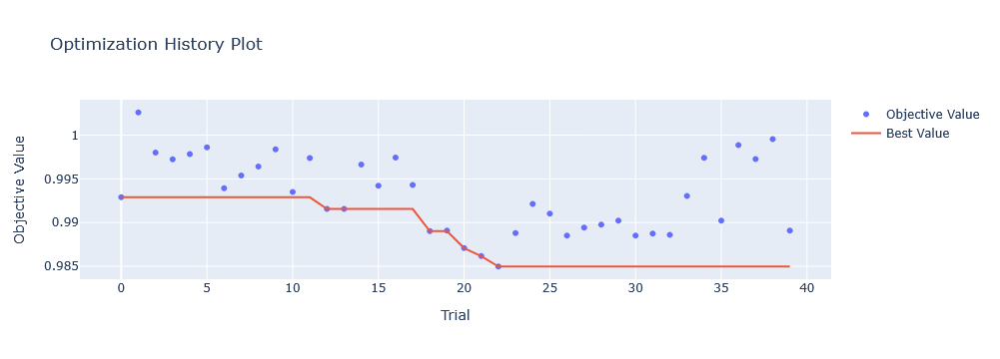

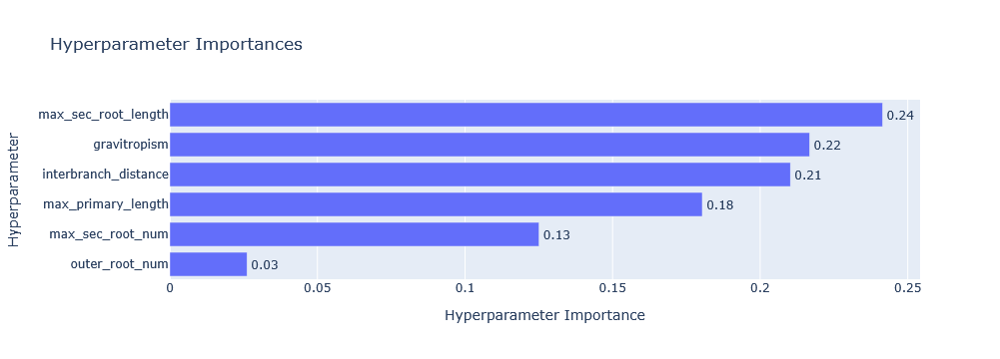

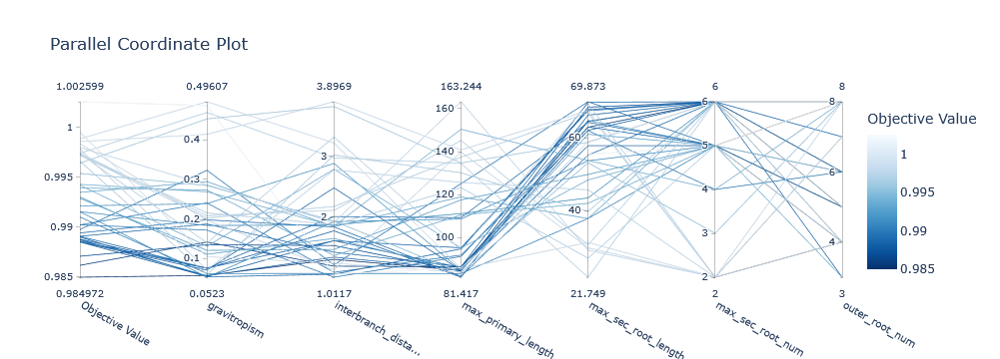

In [7]:
import optuna.visualization as vis
for site, result in optimisation_results.items():
    study=result['study']
    if len(study.get_trials(states=(TrialState.COMPLETE,)))<2:
        continue
    print('Diagnostics:',site)
    display(vis.plot_optimization_history(study))
    display(vis.plot_param_importances(study))
    display(vis.plot_parallel_coordinate(study))

Representative RSA seed: 20000018
Best-fit observed RSA seed: 20000010


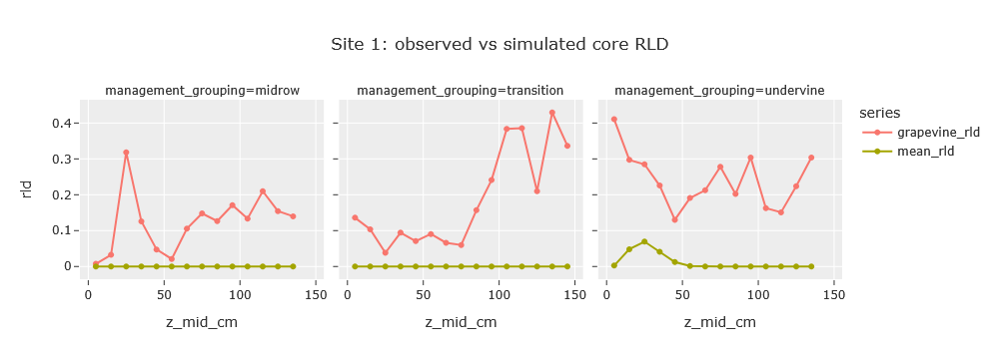

In [8]:
# Generate real (not topology-averaged) root systems using the best parameters.
# One site is chosen for display; set REPRESENTATIVE_SITE after fitting multiple sites.
REPRESENTATIVE_SITE=sites_to_fit[0]
N_ENSEMBLE=20
SEED_OFFSET=20_000_000

fit=optimisation_results[REPRESENTATIVE_SITE]
site_df=fit['site_data']
# Use all sampled core positions for descriptive ensemble diagnostics.
ensemble=[]
rld_vectors=[]
for i in range(N_ENSEMBLE):
    seed=SEED_OFFSET+i
    prediction,architecture=predict_cores(fit['best_parameters'],site_df,seed,
                                          return_architecture=True)
    ensemble.append(architecture)
    rld_vectors.append(prediction.sim_rld.to_numpy(float))
RLD=np.stack(rld_vectors)
mean_vector=RLD.mean(axis=0)
obs_vector=site_df.grapevine_rld.to_numpy(float)
dist_to_ensemble=np.sqrt(np.mean((RLD-mean_vector)**2,axis=1))
dist_to_observed=np.sqrt(np.mean((RLD-obs_vector)**2,axis=1))
representative_index=int(np.argmin(dist_to_ensemble))
best_fit_index=int(np.argmin(dist_to_observed))
representative_rsa=ensemble[representative_index]
best_fit_rsa=ensemble[best_fit_index]

ensemble_rld=site_df[['site','core_id','management_grouping','x_cm','y_cm',
                      'z_mid_cm','grapevine_rld']].copy()
ensemble_rld['mean_rld']=mean_vector
ensemble_rld['sd_rld']=RLD.std(axis=0,ddof=1)
ensemble_rld['q025_rld']=np.quantile(RLD,0.025,axis=0)
ensemble_rld['q975_rld']=np.quantile(RLD,0.975,axis=0)
ensemble_rld['occupancy_probability']=(RLD>0).mean(axis=0)
prefix=REPRESENTATIVE_SITE.lower().replace(' ','_')
ensemble_rld.to_csv(OUT_DIR/f'{prefix}_ensemble_core_rld.csv',index=False)
print('Representative RSA seed:',representative_rsa['seed'])
print('Best-fit observed RSA seed:',best_fit_rsa['seed'])

profiles=(ensemble_rld.groupby(['management_grouping','z_mid_cm'])
          [['grapevine_rld','mean_rld','sd_rld']].mean().reset_index())
profiles=profiles.melt(id_vars=['management_grouping','z_mid_cm'],
                       value_vars=['grapevine_rld','mean_rld'],
                       var_name='series',value_name='rld')
display(px.line(profiles,x='z_mid_cm',y='rld',color='series',
                facet_col='management_grouping',markers=True,
                title=f'{REPRESENTATIVE_SITE}: observed vs simulated core RLD'))

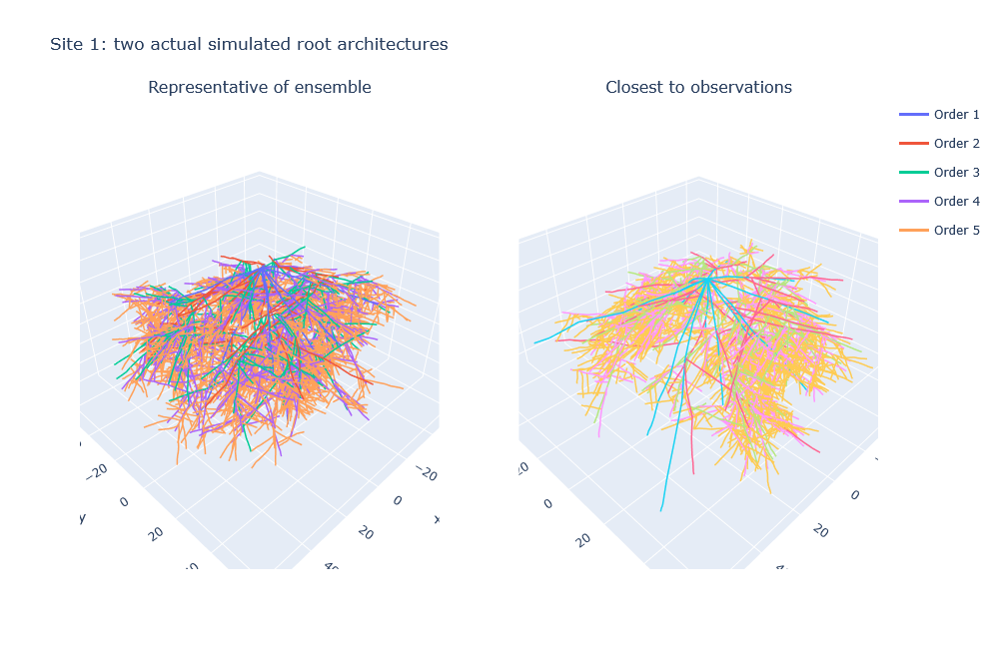

In [9]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 3D architecture plots use actual graph node-parent connectivity.
# These are valid individual stochastic realisations, not an averaged graph.
fig=make_subplots(rows=1,cols=2,
                  specs=[[{'type':'scene'},{'type':'scene'}]],
                  subplot_titles=['Representative of ensemble','Closest to observations'])
for col, (label,architecture) in enumerate([
    ('representative',representative_rsa),('observed_best',best_fit_rsa)],start=1):
    nodes=architecture['nodes'].copy()
    if 'invalid_root' in nodes:
        nodes=nodes.loc[~nodes.invalid_root.fillna(False).astype(bool)]
    positions=nodes.set_index('node_id')[['x','y','z']]
    traces={}
    for _,child in nodes.iterrows():
        parent_id=child['parent_id']
        if pd.isna(parent_id) or parent_id not in positions.index:
            continue
        order=int(child.get('order',1))
        parent=positions.loc[parent_id]
        points=traces.setdefault(order,dict(x=[],y=[],z=[]))
        points['x'].extend([float(parent.x),float(child.x),None])
        points['y'].extend([float(parent.y),float(child.y),None])
        points['z'].extend([float(parent.z),float(child.z),None])
    for order,pts in sorted(traces.items()):
        fig.add_trace(go.Scatter3d(**pts,mode='lines',name=f'Order {order}',
                                   legendgroup=str(order),showlegend=(col==1),
                                   line={'width':3}),row=1,col=col)
fig.update_layout(title=f'{REPRESENTATIVE_SITE}: two actual simulated root architectures',
                  height=650)
display(fig)

**Limitations.** Site/core coordinates must refer to the same simulated grapevine origin. Dry mass is descriptive only here, not automatically a calibration target. Observed diameter-class lengths are treated separately from reported total RLD. An ensemble mean of RLD is never converted to an average hierarchical graph; the displayed architecture is a real replicate closest to the ensemble-mean spatial RLD.